# Repaso de las partes B — seguimiento de código

Lucía es la bibliotecaria del barrio. Cada día presta y recoge libros, ordena signaturas en las estanterías, atiende la pequeña cafetería y prepara la venta solidaria de ejemplares retirados. Para ahorrar tiempo se ha escrito pequeños programas en Python que le ayudan con estas tareas.

Este cuaderno reúne los **ocho ejercicios de seguimiento de código** de los tres últimos exámenes: los cuatro del modelo **A1-WHILE** de IFC33A (18/11/2026) y los cuatro compartidos por los modelos **C-V3** (IFC33A) y **D-V4** (IFC33W). Estos últimos no se duplican porque son idénticos en ambos exámenes.

## Cómo se ha corregido

- La parte B del **A1-WHILE** suma **12 puntos**: 3 por cada seguimiento (2 por la tabla de variables + 1 por la salida exacta).
- La parte B de **C-V3 / D-V4** suma **11 puntos** (3 + 2 + 4 + 2); cada ejercicio conserva aquí su rúbrica original.
- La salida debe copiarse exactamente como la mostraría Python: corchetes, comillas y orden de las líneas cuentan.

## De qué examen es cada ejercicio

| # | Título | Examen | Aparece como | Puntos |
|--:|---|---|---|---:|
| 1 | El carro hasta la marca 8 | IFC33A · A1-WHILE | B1 | 3 |
| 2 | La primera devolución tardía | IFC33A · A1-WHILE | B2 | 3 |
| 3 | Dígitos y letras de una signatura | IFC33A · A1-WHILE | B3 | 3 |
| 4 | La comanda de la cafetería | IFC33A · A1-WHILE | B4 | 3 |
| 5 | Tabla de seguimiento | IFC33A · C-V3 = IFC33W · D-V4 | B1 en ambos | 3 |
| 6 | Construir un string | C-V3 / D-V4 | B2 en C-V3 · B4 en D-V4 | 2 |
| 7 | Espacio y `return` temprano | C-V3 / D-V4 | B3 en C-V3 · B2 en D-V4 | 4 |
| 8 | Impresión dentro y fuera | C-V3 / D-V4 | B4 en C-V3 · B3 en D-V4 | 2 |

<sub>Material del docente — contiene soluciones.</sub>

## Caja de herramientas visual

Ejecutad esta celda una sola vez. Prepara la pizarra y las tablas que usaremos durante el repaso.

In [1]:
#@title Caja de herramientas visual
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import HTML, display

FONDO_PIZARRA = "#164638"
TIZA = "#f3f0df"
TIZA_AMARILLA = "#ffe36e"
TIZA_AZUL = "#a9d7ef"

def dibujar_pizarra(titulo, lineas, ancho=10, alto=3.3, guardar=None):
    """Dibuja una idea con texto y flechas sobre fondo de pizarra."""
    fig, ax = plt.subplots(figsize=(ancho, alto), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.045, 0.91, titulo, color=TIZA_AMARILLA, fontsize=17,
            fontweight="bold", family="DejaVu Sans Mono", va="top")
    cantidad = max(1, len(lineas))
    paso = 0.77 / cantidad
    tamano = 14 if cantidad <= 4 else 12
    for numero, linea in enumerate(lineas):
        if isinstance(linea, tuple):
            texto, color = linea
        else:
            texto, color = linea, TIZA
        ax.text(0.055, 0.78 - numero * paso, texto, color=color,
                fontsize=tamano, family="DejaVu Sans Mono", va="top",
                wrap=True)
    fig.tight_layout(pad=0.5)
    if guardar:
        fig.savefig(guardar, dpi=100, facecolor=FONDO_PIZARRA,
                    bbox_inches="tight")
    display(fig)
    plt.close(fig)

def dibujar_estantes_doble(antes, despues, titulo):
    """Compara dos estantes en la misma pizarra."""
    fig, ax = plt.subplots(figsize=(10, 3.1), dpi=100)
    fig.patch.set_facecolor(FONDO_PIZARRA)
    ax.set_facecolor(FONDO_PIZARRA)
    ax.axis("off")
    ax.text(0.03, 0.94, titulo, transform=ax.transAxes, color=TIZA_AMARILLA,
            fontsize=16, fontweight="bold", family="DejaVu Sans Mono", va="top")
    ancho = max(len(antes), len(despues))
    for fila, (etiqueta, estante) in enumerate((("antes", antes), ("después", despues))):
        y = 0.60 - fila * 0.40
        ax.text(0.04, y + 0.10, etiqueta, transform=ax.transAxes,
                color=TIZA_AZUL, fontsize=13, family="DejaVu Sans Mono")
        for i, letra in enumerate(estante):
            x = 0.21 + 0.73 * i / max(1, ancho)
            w = 0.68 / max(1, ancho)
            ax.add_patch(Rectangle((x, y - 0.05), w, 0.23,
                                   transform=ax.transAxes,
                                   facecolor="#205b49",
                                   edgecolor=TIZA, linewidth=1.2))
            ax.text(x + w / 2, y + 0.065, letra, transform=ax.transAxes,
                    ha="center", va="center", fontsize=15, color=TIZA_AMARILLA,
                    family="DejaVu Sans Mono", fontweight="bold")
    display(fig)
    plt.close(fig)

def tabla_html(filas, columnas):
    """Construye una tabla estática para seguir una vuelta cada vez."""
    estilo = "border:1px solid #b8cbbf;padding:6px 14px;text-align:center;font-size:16px"
    cabecera = "".join(
        f'<th style="{estilo};background:#205b49;color:#fff">{c}</th>'
        for c in columnas
    )
    filas_html = "".join(
        "<tr>" + "".join(
            f'<td style="{estilo};color:#18382e">{fila[c]}</td>'
            for c in columnas
        ) + "</tr>"
        for fila in filas
    )
    return HTML(
        '<table style="border-collapse:collapse">'
        f"<tr>{cabecera}</tr>{filas_html}</table>"
    )

def traza_pasos(filas, columnas, pausa=0):
    """Presenta los datos de cada vuelta en orden."""
    display(tabla_html(filas, columnas))

print("Caja lista: pizarra y tablas de traza.")

Caja lista: pizarra y tablas de traza.


## Ejercicio 1 · El carro hasta la marca 8 (3 puntos)

**Examen:** IFC33A · modelo **A1-WHILE** (18/11/2026) — aparece como **B1**.

### Enunciado exacto

B1. (3 pts) Lucía empuja el carro de devoluciones por el pasillo de la biblioteca. En cada vuelta avanza tres casillas: `codigo` es el marcador de la casilla donde queda el carro e `intentos` cuenta los avances. Se detiene en cuanto alcanza o supera la marca 8. Completa la tabla y escribe la salida exacta.

```python
intentos = 0
codigo = 0
while True:
    codigo = codigo + 3
    intentos = intentos + 1
    if codigo >= 8:
        break
print("encontrado:", codigo)
print("intentos:", intentos)
```

Columnas de la tabla: `vuelta | codigo | intentos`.

### Pizarra

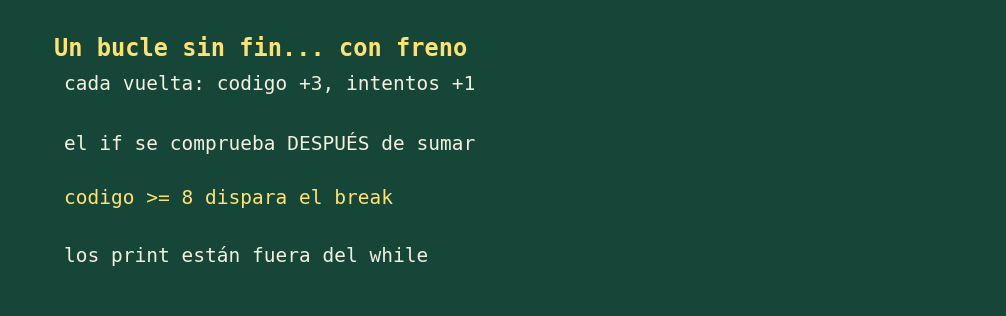

In [2]:
dibujar_pizarra(
    'Un bucle sin fin... con freno',
    [('cada vuelta: codigo +3, intentos +1', TIZA),
     ('el if se comprueba DESPUÉS de sumar', TIZA),
     ('codigo >= 8 dispara el break', TIZA_AMARILLA),
     ('los print están fuera del while', TIZA)],
    ancho=10, alto=3.1,
)

In [3]:
intentos = 0
codigo = 0
while True:
    codigo = codigo + 3
    intentos = intentos + 1
    if codigo >= 8:
        break
print("encontrado:", codigo)
print("intentos:", intentos)

encontrado: 9
intentos: 3


In [4]:
filas_a1_b1 = [{'Vuelta': '1', 'codigo': '3', 'intentos': '1'}, {'Vuelta': '2', 'codigo': '6', 'intentos': '2'}, {'Vuelta': '3', 'codigo': '9', 'intentos': '3 (break)'}]
traza_pasos(filas_a1_b1, ['Vuelta', 'codigo', 'intentos'])

Vuelta,codigo,intentos
1,3,1
2,6,2
3,9,3 (break)


**Paso a paso.** El `while True` no para solo: cada vuelta suma 3 a `codigo` y 1 a `intentos`, y después el `if` comprueba `codigo >= 8`. En la tercera vuelta `codigo` llega a 9, el `break` corta el bucle y los dos `print` de fuera muestran el resultado.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=intentos%20%3D%200%0Acodigo%20%3D%200%0Awhile%20True%3A%0A%20%20%20%20codigo%20%3D%20codigo%20%2B%203%0A%20%20%20%20intentos%20%3D%20intentos%20%2B%201%0A%20%20%20%20if%20codigo%20%3E%3D%208%3A%0A%20%20%20%20%20%20%20%20break%0Aprint%28%22encontrado%3A%22%2C%20codigo%29%0Aprint%28%22intentos%3A%22%2C%20intentos%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Tabla: columnas correctas según la lista dada. | 0,5 |
| Tabla: valores al final de cada vuelta correctos, incluida la vuelta del `break`. | 1 |
| Tabla: sin filas ni columnas inventadas. | 0,5 |
| Salida: contenido correcto. | 0,5 |
| Salida: orden y formato exactos (corchetes, comillas, orden de líneas). | 0,5 |

#### Errores frecuentes

- Parar una vuelta antes (`codigo = 6`) o una después (`codigo = 12`): la condición es `>= 8` y 6 no la cumple.
- No contar la vuelta del `break`: `intentos` también sube en ella y acaba en 3.
- Escribir las líneas de salida en orden cambiado o sin los textos `encontrado:` / `intentos:`.

## Ejercicio 2 · La primera devolución tardía (3 puntos)

**Examen:** IFC33A · modelo **A1-WHILE** (18/11/2026) — aparece como **B2**.

### Enunciado exacto

B2. (3 pts) Lucía revisa la lista de días de retraso de las devoluciones de hoy y quiere la posición de la primera que supera los 10 días. Completa la tabla y escribe la salida exacta.

```python
datos = [7, 4, 12, 9, 3]
posicion = 0
encontrado = -1
for d in datos:
    if d > 10:
        encontrado = posicion
        break
    posicion = posicion + 1
print("posicion:", encontrado)
```

Columnas de la tabla: `vuelta | d | posicion | encontrado`.

Nota: `encontrado` vale -1 antes de empezar el bucle; anota su valor al final de cada vuelta.

### Pizarra

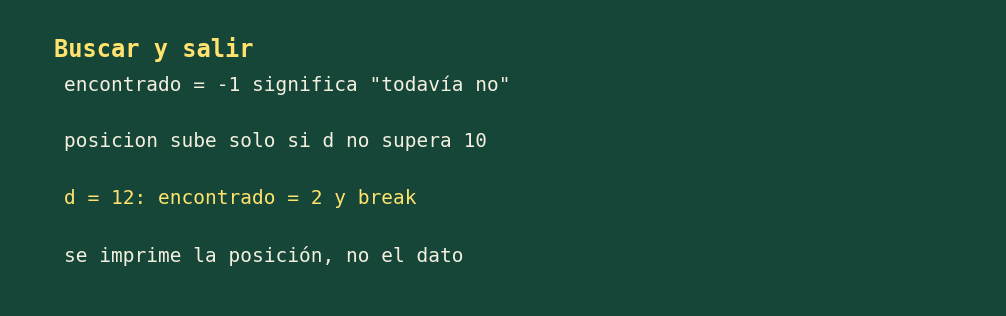

In [5]:
dibujar_pizarra(
    'Buscar y salir',
    [('encontrado = -1 significa "todavía no"', TIZA),
     ('posicion sube solo si d no supera 10', TIZA),
     ('d = 12: encontrado = 2 y break', TIZA_AMARILLA),
     ('se imprime la posición, no el dato', TIZA)],
    ancho=10, alto=3.1,
)

In [6]:
datos = [7, 4, 12, 9, 3]
posicion = 0
encontrado = -1
for d in datos:
    if d > 10:
        encontrado = posicion
        break
    posicion = posicion + 1
print("posicion:", encontrado)

posicion: 2


In [7]:
filas_a1_b2 = [{'Vuelta': '1', 'd': '7', 'posicion': '1', 'encontrado': '-1'}, {'Vuelta': '2', 'd': '4', 'posicion': '2', 'encontrado': '-1'}, {'Vuelta': '3', 'd': '12', 'posicion': '2', 'encontrado': '2 (break)'}]
traza_pasos(filas_a1_b2, ['Vuelta', 'd', 'posicion', 'encontrado'])

Vuelta,d,posicion,encontrado
1,7,1,-1
2,4,2,-1
3,12,2,2 (break)


**Paso a paso.** `posicion` solo aumenta cuando `d` no supera 10, porque el incremento está después del `if`. Con `d = 12` se ejecuta `encontrado = posicion` (que ya vale 2) y el `break` sale del bucle sin volver a tocar `posicion`. La salida es la posición del primer retraso mayor de 10: 2.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=datos%20%3D%20%5B7%2C%204%2C%2012%2C%209%2C%203%5D%0Aposicion%20%3D%200%0Aencontrado%20%3D%20-1%0Afor%20d%20in%20datos%3A%0A%20%20%20%20if%20d%20%3E%2010%3A%0A%20%20%20%20%20%20%20%20encontrado%20%3D%20posicion%0A%20%20%20%20%20%20%20%20break%0A%20%20%20%20posicion%20%3D%20posicion%20%2B%201%0Aprint%28%22posicion%3A%22%2C%20encontrado%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Tabla: columnas correctas según la lista dada. | 0,5 |
| Tabla: valores al final de cada vuelta correctos, incluida la vuelta del `break`. | 1 |
| Tabla: sin filas ni columnas inventadas. | 0,5 |
| Salida: contenido correcto. | 0,5 |
| Salida: orden y formato exactos (corchetes, comillas, orden de líneas). | 0,5 |

#### Errores frecuentes

- Anotar `posicion = 3` en la vuelta del `break`: el `posicion = posicion + 1` no llega a ejecutarse.
- Escribir el dato encontrado (12) en vez de su posición (2).
- Olvidar el texto `posicion:` en la salida o escribir el valor -1 inicial.

## Ejercicio 3 · Dígitos y letras de una signatura (3 puntos)

**Examen:** IFC33A · modelo **A1-WHILE** (18/11/2026) — aparece como **B3**.

### Enunciado exacto

B3. (3 pts) Lucía copia la signatura «a3b7c» y separa los dígitos, que apunta para el inventario, de las letras. Completa la tabla y escribe la salida exacta.

```python
codigo = "a3b7c"
digitos = []
letras = 0
for c in codigo:
    if c in "0123456789":
        digitos.append(c)
    else:
        letras = letras + 1
print(digitos)
print("letras:", letras)
```

Columnas de la tabla: `vuelta | c | digitos | letras`.

### Pizarra

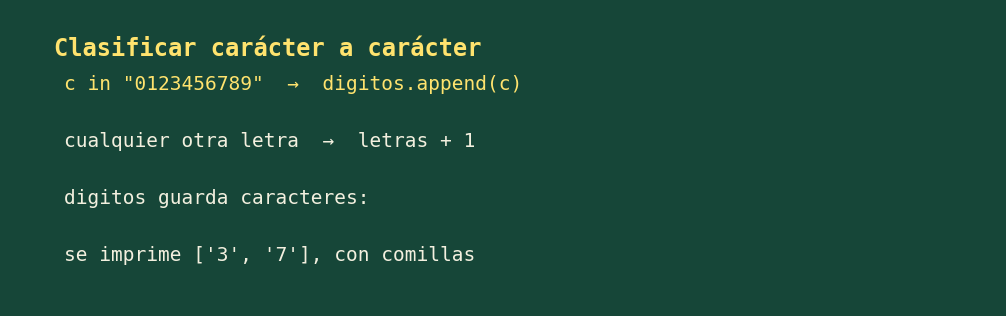

In [8]:
dibujar_pizarra(
    'Clasificar carácter a carácter',
    [('c in "0123456789"  →  digitos.append(c)', TIZA_AMARILLA),
     ('cualquier otra letra  →  letras + 1', TIZA),
     ('digitos guarda caracteres:', TIZA),
     ("se imprime ['3', '7'], con comillas", TIZA)],
    ancho=10, alto=3.1,
)

In [9]:
codigo = "a3b7c"
digitos = []
letras = 0
for c in codigo:
    if c in "0123456789":
        digitos.append(c)
    else:
        letras = letras + 1
print(digitos)
print("letras:", letras)

['3', '7']
letras: 3


In [10]:
filas_a1_b3 = [{'Vuelta': '1', 'c': 'a', 'digitos': '[]', 'letras': '1'}, {'Vuelta': '2', 'c': '3', 'digitos': "['3']", 'letras': '1'}, {'Vuelta': '3', 'c': 'b', 'digitos': "['3']", 'letras': '2'}, {'Vuelta': '4', 'c': '7', 'digitos': "['3', '7']", 'letras': '2'}, {'Vuelta': '5', 'c': 'c', 'digitos': "['3', '7']", 'letras': '3'}]
traza_pasos(filas_a1_b3, ['Vuelta', 'c', 'digitos', 'letras'])

Vuelta,c,digitos,letras
1,a,[],1
2,3,['3'],1
3,b,['3'],2
4,7,"['3', '7']",2
5,c,"['3', '7']",3


**Paso a paso.** El `for` recorre cada carácter de `a3b7c`. Si está en `0123456789` va a la lista `digitos` (como carácter, entre comillas); si no, `letras` sube en 1. Al final hay dos dígitos guardados y tres letras contadas.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=codigo%20%3D%20%22a3b7c%22%0Adigitos%20%3D%20%5B%5D%0Aletras%20%3D%200%0Afor%20c%20in%20codigo%3A%0A%20%20%20%20if%20c%20in%20%220123456789%22%3A%0A%20%20%20%20%20%20%20%20digitos.append%28c%29%0A%20%20%20%20else%3A%0A%20%20%20%20%20%20%20%20letras%20%3D%20letras%20%2B%201%0Aprint%28digitos%29%0Aprint%28%22letras%3A%22%2C%20letras%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Tabla: columnas correctas según la lista dada. | 0,5 |
| Tabla: valores al final de cada vuelta correctos. | 1 |
| Tabla: sin filas ni columnas inventadas. | 0,5 |
| Salida: contenido correcto. | 0,5 |
| Salida: orden y formato exactos (corchetes, comillas, orden de líneas). | 0,5 |

#### Errores frecuentes

- Escribir `[3, 7]` sin comillas: la lista guarda los caracteres `'3'` y `'7'`, no los números.
- Contar las letras en la columna `digitos` o al revés.
- Escribir la salida sin corchetes ni comillas (`3, 7` no es lo que imprime Python).

## Ejercicio 4 · La comanda de la cafetería (3 puntos)

**Examen:** IFC33A · modelo **A1-WHILE** (18/11/2026) — aparece como **B4**.

### Enunciado exacto

B4. (3 pts) Lucía apunta la comanda de una mesa de la cafetería de la biblioteca: suma el total de lo que está en el menú y cuenta aparte lo que no está. Completa la tabla y escribe la salida exacta.

```python
menu = {"te": 2, "cafe": 1, "agua": 1}
pedido = ["te", "agua", "te", "zumo"]
total = 0
desconocidos = 0
for p in pedido:
    precio = menu.get(p, -1)
    if precio >= 0:
        total = total + precio
    else:
        desconocidos = desconocidos + 1
print("total:", total)
print("desconocidos:", desconocidos)
```

Columnas de la tabla: `vuelta | p | precio | total | desconocidos`.

Nota: `precio` se reasigna en cada vuelta; anota su valor al final de la vuelta correspondiente.

### Pizarra

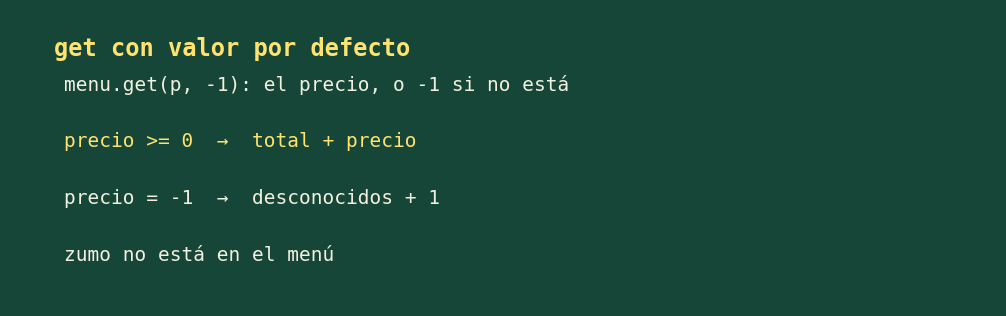

In [11]:
dibujar_pizarra(
    'get con valor por defecto',
    [('menu.get(p, -1): el precio, o -1 si no está', TIZA),
     ('precio >= 0  →  total + precio', TIZA_AMARILLA),
     ('precio = -1  →  desconocidos + 1', TIZA),
     ('zumo no está en el menú', TIZA)],
    ancho=10, alto=3.1,
)

In [12]:
menu = {"te": 2, "cafe": 1, "agua": 1}
pedido = ["te", "agua", "te", "zumo"]
total = 0
desconocidos = 0
for p in pedido:
    precio = menu.get(p, -1)
    if precio >= 0:
        total = total + precio
    else:
        desconocidos = desconocidos + 1
print("total:", total)
print("desconocidos:", desconocidos)

total: 5
desconocidos: 1


In [13]:
filas_a1_b4 = [{'Vuelta': '1', 'p': 'te', 'precio': '2', 'total': '2', 'desconocidos': '0'}, {'Vuelta': '2', 'p': 'agua', 'precio': '1', 'total': '3', 'desconocidos': '0'}, {'Vuelta': '3', 'p': 'te', 'precio': '2', 'total': '5', 'desconocidos': '0'}, {'Vuelta': '4', 'p': 'zumo', 'precio': '-1', 'total': '5', 'desconocidos': '1'}]
traza_pasos(filas_a1_b4, ['Vuelta', 'p', 'precio', 'total', 'desconocidos'])

Vuelta,p,precio,total,desconocidos
1,te,2,2,0
2,agua,1,3,0
3,te,2,5,0
4,zumo,-1,5,1


**Paso a paso.** En cada vuelta `precio` se reasigna con `menu.get(p, -1)`: devuelve el precio si el producto está en el menú y -1 si no. Los tres primeros pedidos están y suman 5; `zumo` da -1, no suma nada y solo aumenta `desconocidos`.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=menu%20%3D%20%7B%22te%22%3A%202%2C%20%22cafe%22%3A%201%2C%20%22agua%22%3A%201%7D%0Apedido%20%3D%20%5B%22te%22%2C%20%22agua%22%2C%20%22te%22%2C%20%22zumo%22%5D%0Atotal%20%3D%200%0Adesconocidos%20%3D%200%0Afor%20p%20in%20pedido%3A%0A%20%20%20%20precio%20%3D%20menu.get%28p%2C%20-1%29%0A%20%20%20%20if%20precio%20%3E%3D%200%3A%0A%20%20%20%20%20%20%20%20total%20%3D%20total%20%2B%20precio%0A%20%20%20%20else%3A%0A%20%20%20%20%20%20%20%20desconocidos%20%3D%20desconocidos%20%2B%201%0Aprint%28%22total%3A%22%2C%20total%29%0Aprint%28%22desconocidos%3A%22%2C%20desconocidos%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Tabla: columnas correctas según la lista dada. | 0,5 |
| Tabla: valores al final de cada vuelta correctos. | 1 |
| Tabla: sin filas ni columnas inventadas. | 0,5 |
| Salida: contenido correcto. | 0,5 |
| Salida: orden y formato exactos (corchetes, comillas, orden de líneas). | 0,5 |

#### Errores frecuentes

- Tratar `zumo` como precio 0: `get` devuelve -1 y cuenta como desconocido, no suma al total.
- Cambiar `total` en la última vuelta: se queda en 5.
- Intercambiar las líneas de salida: primero `total`, después `desconocidos`.

## Ejercicio 5 · Tabla de seguimiento (3 puntos)

**Examen:** IFC33A · **C-V3** (B1) y también IFC33W · **D-V4** (B1) — mismo ejercicio.


### Enunciado exacto

B1. (3 pts) Lucía revisa los libros devueltos: la lista indica cuántos días de retraso trae cada uno. Cuenta cuántos libros ha revisado y pone multa a los que llegan con 3 días o más. Completa la tabla con el valor de las variables al final de cada vuelta y escribe lo que imprime.

```python
def revisar(retrasos):
    multados = 0
    revisados = 0
    for d in retrasos:
        revisados = revisados + 1
        if d >= 3:
            multados = multados + 1
    print("Multados:", multados)
    print("Revisados:", revisados)

revisar([4, 1, 5, 0, 6])
```

### Pizarra

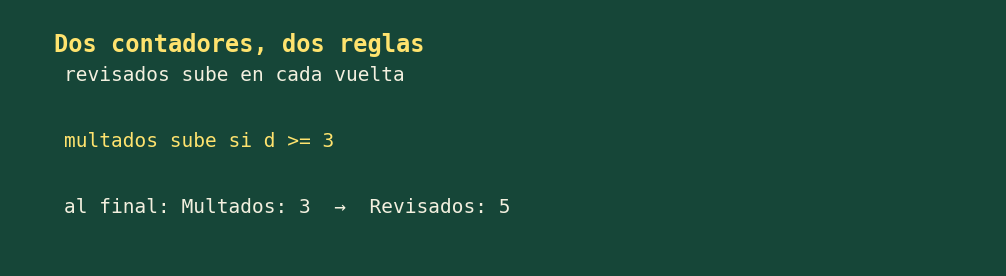

In [14]:
dibujar_pizarra(
    'Dos contadores, dos reglas',
    [('revisados sube en cada vuelta', TIZA),
    ('multados sube si d >= 3', TIZA_AMARILLA),
    ('al final: Multados: 3  →  Revisados: 5', TIZA)],
    ancho=10, alto=2.7,
)

In [15]:
def revisar(retrasos):
    multados = 0
    revisados = 0
    for d in retrasos:
        revisados = revisados + 1
        if d >= 3:
            multados = multados + 1
    print("Multados:", multados)
    print("Revisados:", revisados)

revisar([4, 1, 5, 0, 6])

Multados: 3
Revisados: 5


In [16]:
filas_b1 = [{'Vuelta': '1', 'd': '4', 'multados': '1', 'revisados': '1'}, {'Vuelta': '2', 'd': '1', 'multados': '1', 'revisados': '2'}, {'Vuelta': '3', 'd': '5', 'multados': '2', 'revisados': '3'}, {'Vuelta': '4', 'd': '0', 'multados': '2', 'revisados': '4'}, {'Vuelta': '5', 'd': '6', 'multados': '3', 'revisados': '5'}]
traza_pasos(filas_b1, ["Vuelta", "d", "multados", "revisados"])

Vuelta,d,multados,revisados
1,4,1,1
2,1,1,2
3,5,2,3
4,0,2,4
5,6,3,5


**Paso a paso.** Primero, `revisados` aumenta una vez en cada vuelta. Después se comprueba `d >= 3`: las vueltas 1, 3 y 5 suman una multa. La tabla termina con `multados = 3` y `revisados = 5`; los dos `print` están después del bucle.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20revisar%28retrasos%29%3A%0A%20%20%20%20multados%20%3D%200%0A%20%20%20%20revisados%20%3D%200%0A%20%20%20%20for%20d%20in%20retrasos%3A%0A%20%20%20%20%20%20%20%20revisados%20%3D%20revisados%20%2B%201%0A%20%20%20%20%20%20%20%20if%20d%20%3E%3D%203%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20multados%20%3D%20multados%20%2B%201%0A%20%20%20%20print%28%22Multados%3A%22%2C%20multados%29%0A%20%20%20%20print%28%22Revisados%3A%22%2C%20revisados%29%0A%0Arevisar%28%5B4%2C%201%2C%205%2C%200%2C%206%5D%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Tabla: 0,4 por cada fila completa. | 2 |
| Se acepta crédito parcial por columna si una fila está parcialmente bien. | — |
| Salida `Multados: 3`. | 0,5 |
| Salida `Revisados: 5`. | 0,5 |

#### Errores frecuentes

- Escribir `None` en lugar de las líneas que muestran los `print`.
- Omitir el texto `Multados:` o `Revisados:` en las salidas.
- Aumentar `multados` también cuando `d` es menor que 3.

## Ejercicio 6 · Construir un string (2 puntos)

**Examen:** IFC33A · **C-V3** (B2) y también IFC33W · **D-V4** (B4) — mismo ejercicio.


### Enunciado exacto

B2. (2 pts) Han llegado novelas nuevas y Lucía coloca una en cada hueco libre de la estantería. Indica exactamente qué imprime cada línea. (1,5 ptos la primera, 0,5 ptos la segunda)

```python
estante = "N.C."
nuevo = ""
vacios = 0
for c in estante:
    if c == ".":
        nuevo = nuevo + "N"
        vacios = vacios + 1
    else:
        nuevo = nuevo + c

print(nuevo)
print(vacios)
```

### Pizarra

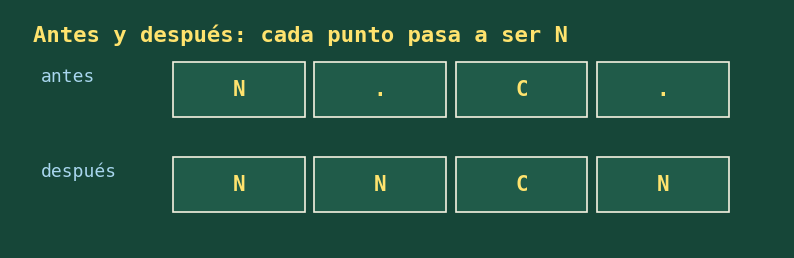

In [17]:
dibujar_estantes_doble("N.C.", "NNCN", "Antes y después: cada punto pasa a ser N")

In [18]:
estante = "N.C."
nuevo = ""
vacios = 0
for c in estante:
    if c == ".":
        nuevo = nuevo + "N"
        vacios = vacios + 1
    else:
        nuevo = nuevo + c

print(nuevo)
print(vacios)

NNCN
2


In [19]:
filas_e6 = [{'Vuelta': '1', 'c': 'N', 'nuevo': 'N', 'vacios': '0'}, {'Vuelta': '2', 'c': '.', 'nuevo': 'NN', 'vacios': '1'}, {'Vuelta': '3', 'c': 'C', 'nuevo': 'NNC', 'vacios': '1'}, {'Vuelta': '4', 'c': '.', 'nuevo': 'NNCN', 'vacios': '2'}]
traza_pasos(filas_e6, ['Vuelta', 'c', 'nuevo', 'vacios'])

Vuelta,c,nuevo,vacios
1,N,N,0
2,.,NN,1
3,C,NNC,1
4,.,NNCN,2


**Paso a paso.** El `for` recorre las letras de `N.C.`. Copia la primera `N`, cambia `.` por `N`, copia `C` y cambia el último `.` por `N`. El nuevo estante es `NNCN`; hay 2 huecos sustituidos. Se imprimen esas dos líneas.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=estante%20%3D%20%22N.C.%22%0Anuevo%20%3D%20%22%22%0Avacios%20%3D%200%0Afor%20c%20in%20estante%3A%0A%20%20%20%20if%20c%20%3D%3D%20%22.%22%3A%0A%20%20%20%20%20%20%20%20nuevo%20%3D%20nuevo%20%2B%20%22N%22%0A%20%20%20%20%20%20%20%20vacios%20%3D%20vacios%20%2B%201%0A%20%20%20%20else%3A%0A%20%20%20%20%20%20%20%20nuevo%20%3D%20nuevo%20%2B%20c%0A%0Aprint%28nuevo%29%0Aprint%28vacios%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Primera línea: `NNCN`. | 1,5 |
| Segunda línea: `2`. | 0,5 |

#### Errores frecuentes

- Cambiar letras que no son `.`.
- No conservar el resto del estante en el string nuevo.

## Ejercicio 7 · Espacio y `return` temprano (4 puntos)

**Examen:** IFC33A · **C-V3** (B3) y también IFC33W · **D-V4** (B2) — mismo ejercicio.


### Enunciado exacto

B3. (4 pts) Esta función calcula cuántos libros caben, en orden, en el espacio libre de una balda: la lista indica el grosor de cada libro en centímetros y espacio, los centímetros libres. Escribe exactamente lo que imprime el programa y responde: ¿cuántas vueltas da el bucle en la primera llamada? (1 pto cada línea impresa y 1 pto la pregunta)

```python
def caben(grosores, espacio):
    libros = 0
    for g in grosores:
        if g > espacio:
            return libros
        espacio = espacio - g
        libros = libros + 1
    return libros

print(caben([2, 3], 4))
print(caben([1, 1], 5))
print(caben([7], 5))
```

### Pizarra

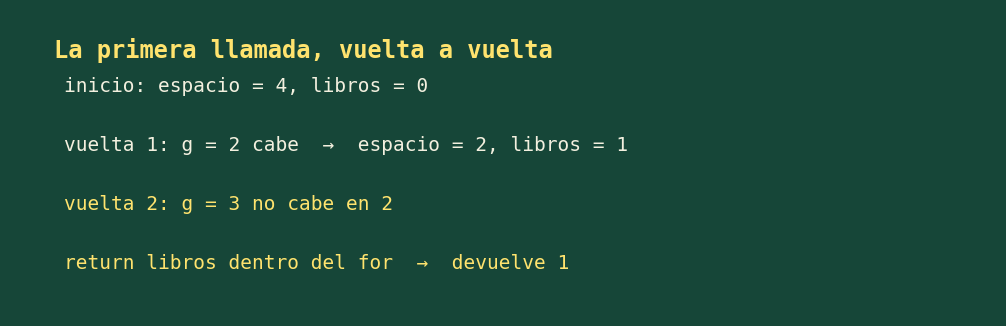

In [20]:
dibujar_pizarra(
    'La primera llamada, vuelta a vuelta',
    [('inicio: espacio = 4, libros = 0', TIZA),
    ('vuelta 1: g = 2 cabe  →  espacio = 2, libros = 1', TIZA),
    ('vuelta 2: g = 3 no cabe en 2', TIZA_AMARILLA),
    ('return libros dentro del for  →  devuelve 1', TIZA_AMARILLA)],
    ancho=10, alto=3.2,
)

In [21]:
def caben(grosores, espacio):
    libros = 0
    for g in grosores:
        if g > espacio:
            return libros
        espacio = espacio - g
        libros = libros + 1
    return libros

print(caben([2, 3], 4))
print(caben([1, 1], 5))
print(caben([7], 5))

1
2
0


In [22]:
filas_b3 = [{'Vuelta': '1', 'g': '2', 'espacio antes': '4', '¿cabe?': 'sí', 'libros': '1'}, {'Vuelta': '2', 'g': '3', 'espacio antes': '2', '¿cabe?': 'no → return', 'libros': '1'}]
traza_pasos(filas_b3, ["Vuelta", "g", "espacio antes", "¿cabe?", "libros"])

Vuelta,g,espacio antes,¿cabe?,libros
1,2,4,sí,1
2,3,2,no → return,1


**Paso a paso.** En la primera llamada, el libro de grosor 2 cabe en 4: quedan 2 cm y `libros` pasa a 1. El bucle llega a la segunda vuelta con `g = 3`; no cabe en los 2 cm. El `return libros` de dentro termina la función y devuelve 1. Por eso son **2 vueltas**. En la segunda llamada caben los dos libros y devuelve 2; en la tercera el libro no cabe desde el principio y devuelve 0.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20caben%28grosores%2C%20espacio%29%3A%0A%20%20%20%20libros%20%3D%200%0A%20%20%20%20for%20g%20in%20grosores%3A%0A%20%20%20%20%20%20%20%20if%20g%20%3E%20espacio%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20return%20libros%0A%20%20%20%20%20%20%20%20espacio%20%3D%20espacio%20-%20g%0A%20%20%20%20%20%20%20%20libros%20%3D%20libros%20%2B%201%0A%20%20%20%20return%20libros%0A%0Aprint%28caben%28%5B2%2C%203%5D%2C%204%29%29%0Aprint%28caben%28%5B1%2C%201%5D%2C%205%29%29%0Aprint%28caben%28%5B7%5D%2C%205%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Primera línea impresa: `1`. | 1 |
| Segunda línea impresa: `2`. | 1 |
| Tercera línea impresa: `0`. | 1 |
| Primera llamada: 2 vueltas. | 1 |

#### Errores frecuentes

- Contar el `return` como si el bucle continuara con más elementos.
- No descontar el grosor que sí cabe antes de comprobar la siguiente vuelta.

## Ejercicio 8 · Impresión dentro y fuera (2 puntos)

**Examen:** IFC33A · **C-V3** (B4) y también IFC33W · **D-V4** (B3) — mismo ejercicio.


### Enunciado exacto

B4. (2 pts) Lucía aparta todo lo que llega menos las revistas para ponerle el sello de la biblioteca. Escribe exactamente lo que aparece en pantalla al ejecutar este programa. (1 pto la lista, 0,5 ptos cada una de las otras dos líneas)

```python
def sellar(lote):
    sellados = []
    for libro in lote:
        if libro != "revista":
            sellados.append(libro)
    print(len(lote))
    return sellados

r = sellar(["novela", "revista", "comic"])
print(r)
print(len(r))
```

### Pizarra

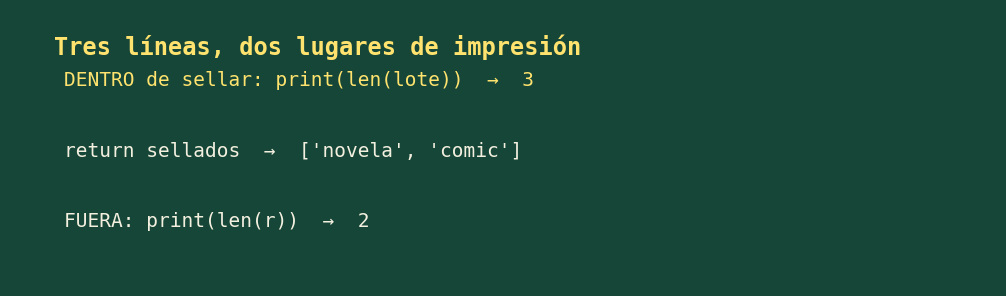

In [23]:
dibujar_pizarra(
    'Tres líneas, dos lugares de impresión',
    [('DENTRO de sellar: print(len(lote))  →  3', TIZA_AMARILLA),
    ("return sellados  →  ['novela', 'comic']", TIZA),
    ('FUERA: print(len(r))  →  2', TIZA)],
    ancho=10, alto=2.9,
)

In [24]:
def sellar(lote):
    sellados = []
    for libro in lote:
        if libro != "revista":
            sellados.append(libro)
    print(len(lote))
    return sellados

r = sellar(["novela", "revista", "comic"])
print(r)
print(len(r))

3
['novela', 'comic']
2


In [25]:
filas_e8 = [{'Vuelta': '1', 'libro': 'novela', 'sellados': "['novela']"}, {'Vuelta': '2', 'libro': 'revista', 'sellados': "['novela']"}, {'Vuelta': '3', 'libro': 'comic', 'sellados': "['novela', 'comic']"}]
traza_pasos(filas_e8, ['Vuelta', 'libro', 'sellados'])

Vuelta,libro,sellados
1,novela,['novela']
2,revista,['novela']
3,comic,"['novela', 'comic']"


**Paso a paso.** Al llamar a `sellar`, el `print` que está dentro muestra la longitud de `lote`, que es 3. La función devuelve la lista sin `revista`. Después, fuera de la función, el programa muestra esa lista y su longitud, 2.

[Ver paso a paso en PythonTutor](https://pythontutor.com/visualize.html#code=def%20sellar%28lote%29%3A%0A%20%20%20%20sellados%20%3D%20%5B%5D%0A%20%20%20%20for%20libro%20in%20lote%3A%0A%20%20%20%20%20%20%20%20if%20libro%20%21%3D%20%22revista%22%3A%0A%20%20%20%20%20%20%20%20%20%20%20%20sellados.append%28libro%29%0A%20%20%20%20print%28len%28lote%29%29%0A%20%20%20%20return%20sellados%0A%0Ar%20%3D%20sellar%28%5B%22novela%22%2C%20%22revista%22%2C%20%22comic%22%5D%29%0Aprint%28r%29%0Aprint%28len%28r%29%29&cumulative=false&curInstr=0&heapPrimitives=nevernest&mode=display&origin=opt-frontend.js&py=311&rawInputLstJson=%5B%5D&textReferences=false)

#### Rúbrica

| Criterio | Puntos |
|---|---:|
| Lista `['novela', 'comic']`. | 1 |
| Primera línea `3`. | 0,5 |
| Última línea `2`. | 0,5 |

#### Errores frecuentes

- Olvidar el `3` que imprime la función por dentro.
- Confundir la lista devuelta con el lote original.

# Resumen final

| Examen | Ejercicio | Respuesta oficial | Puntos |
|---|---|---|---:|
| IFC33A · A1-WHILE | B1 | tabla: `codigo` 3, 6, 9 e `intentos` 1, 2, 3; `encontrado: 9`, `intentos: 3` | 3 |
| IFC33A · A1-WHILE | B2 | tabla de 3 filas; `posicion: 2` | 3 |
| IFC33A · A1-WHILE | B3 | tabla de 5 filas; `['3', '7']`, `letras: 3` | 3 |
| IFC33A · A1-WHILE | B4 | tabla de 4 filas; `total: 5`, `desconocidos: 1` | 3 |
| C-V3 = D-V4 | B1 (en ambos) | tabla de 5 filas; `Multados: 3`, `Revisados: 5` | 3 |
| C-V3 / D-V4 | B2 en C-V3 · B4 en D-V4 | `NNCN`; `2` | 2 |
| C-V3 / D-V4 | B3 en C-V3 · B2 en D-V4 | `1`, `2`, `0`; 2 vueltas en la primera llamada | 4 |
| C-V3 / D-V4 | B4 en C-V3 · B3 en D-V4 | `3`; `['novela', 'comic']`; `2` | 2 |
| **Total por examen** | | **A1-WHILE: 12 · C-V3/D-V4: 11** | **23** |

## Dudas frecuentes

**¿Por qué el carro de B1 (A1-WHILE) para en la casilla 9 y no en la 8?**  
`codigo` sube de 3 en 3: 3, 6, 9. La condición es `>= 8`, así que la primera marca que la cumple es 9; el bucle nunca pisa la casilla 8.

**¿Por qué en B2 (A1-WHILE) `posicion` se queda en 2 en la vuelta del `break`?**  
El `posicion = posicion + 1` está después del `if`. Cuando `d = 12` dispara el `break`, esa línea ya no se ejecuta y `posicion` conserva el 2.

**¿Por qué `['3', '7']` lleva comillas en B3 (A1-WHILE)?**  
`digitos.append(c)` guarda el carácter, no el número. Python muestra las listas de cadenas con comillas: `['3', '7']`, no `[3, 7]`.

**¿Por qué son 2 vueltas en la primera llamada de `caben` (ejercicio 7)?**  
El bucle comprueba primero el grosor 2, que cabe, y después el grosor 3, que no cabe en los 2 cm restantes. Esa comprobación sucede en la segunda vuelta.

**¿Por qué en el ejercicio 8 aparece un `3` antes que la lista?**  
El `print(len(lote))` está dentro de `sellar` y se ejecuta al llamarla, antes de que el programa muestre `r` y `len(r)` fuera de la función.

**¿Cómo de exacta tiene que ser la salida?**  
Como la mostraría Python: mismo orden de líneas, corchetes y comillas donde corresponda. En A1-WHILE la salida puntúa aparte de la tabla (1 punto: 0,5 contenido + 0,5 formato).